In [1]:
# Importing libraries for analysis and prediction
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("customer_churn_dataset-training-master.csv")
df.shape

(440833, 12)

## Lets Do Some Exploratory Data Analysis

In [3]:
df.head(5)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  str    
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  str    
 8   Contract Length    440832 non-null  str    
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), str(3)
memory usage: 40.4 MB


In [5]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [6]:
# Customer id is not a useful feature going forward so lets remove it
df.drop("CustomerID", axis=1, inplace=True)
df.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [7]:
df[df.isna().any(axis=1)]

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


There is just one row with null values. Previously it was removed by its
position in the DataFrame (`df.drop(199295)`), which only works for this exact
file — any edit to the CSV would delete the wrong row, or none. Drop by
condition instead.

In [8]:
before = len(df)
df.dropna(inplace=True)
print(f"dropped {before - len(df)} row(s) containing nulls -> {len(df)} rows remain")

dropped 1 row(s) containing nulls -> 440832 rows remain


In [9]:
df.isna().sum()

Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

1. There are no duplicate rows in the dataframe
2. Nan values have been removed previously

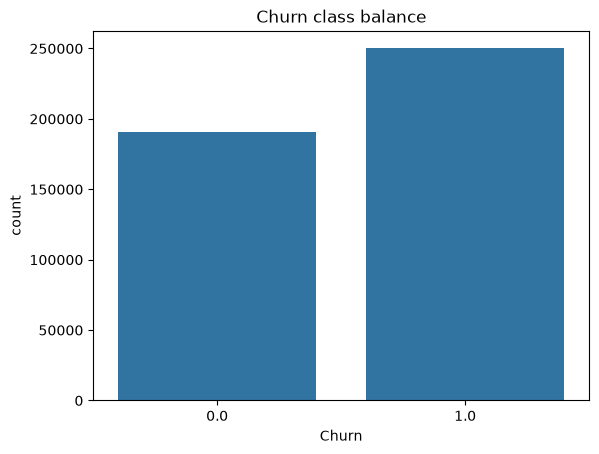

In [11]:
sns.countplot(df, x="Churn")
plt.title("Churn class balance")
plt.show()

In [12]:
df.Churn.value_counts(normalize=True).round(4)

Churn
1.0    0.5671
0.0    0.4329
Name: proportion, dtype: float64

## Mild Unbalancing Found, Sampling Not Required to Train Model

### Categorical features encoded for model training

`Gender`, `Subscription Type` and `Contract Length` are **nominal** — they have
no natural order. `LabelEncoder` assigns them arbitrary integers (Basic=1,
Premium=2, Standard=3), which tells the model that Premium sits "between" Basic
and Standard. That is not true, and it invites a model to split on a boundary
that means nothing.

One-hot encoding gives each category its own 0/1 column instead.

In [13]:
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()
categorical_features

['Gender', 'Subscription Type', 'Contract Length']

In [14]:
# One-hot encode the nominal columns. Churn is the target, never a feature.
categorical_features = [c for c in categorical_features if c != "Churn"]

df = pd.get_dummies(df, columns=categorical_features)
print("features after one-hot encoding:", df.shape[1] - 1)
df.head()

features after one-hot encoding: 15


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
0,30.0,39.0,14.0,5.0,18.0,932.0,17.0,1.0,True,False,False,False,True,True,False,False
1,65.0,49.0,1.0,10.0,8.0,557.0,6.0,1.0,True,False,True,False,False,False,True,False
2,55.0,14.0,4.0,6.0,18.0,185.0,3.0,1.0,True,False,True,False,False,False,False,True
3,58.0,38.0,21.0,7.0,7.0,396.0,29.0,1.0,False,True,False,False,True,False,True,False
4,23.0,32.0,20.0,5.0,8.0,617.0,20.0,1.0,False,True,True,False,False,False,True,False


#### Train Test Split

In [15]:
# Select by name, not position: get_dummies appends the new columns *after*
# Churn, so df.iloc[:, :-1] would silently drop a real feature.
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("X:", X.shape, "| y:", y.shape)
X.head()

X: (440832, 15) | y: (440832,)


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
0,30.0,39.0,14.0,5.0,18.0,932.0,17.0,True,False,False,False,True,True,False,False
1,65.0,49.0,1.0,10.0,8.0,557.0,6.0,True,False,True,False,False,False,True,False
2,55.0,14.0,4.0,6.0,18.0,185.0,3.0,True,False,True,False,False,False,False,True
3,58.0,38.0,21.0,7.0,7.0,396.0,29.0,False,True,False,False,True,False,True,False
4,23.0,32.0,20.0,5.0,8.0,617.0,20.0,False,True,True,False,False,False,True,False


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (352665, 15) | test: (88167, 15)


#### Train every model once, then compare


Logistic Regression  ||  test accuracy: 0.8964
              precision    recall  f1-score   support

         0.0     0.8600    0.9079    0.8833     38063
         1.0     0.9269    0.8877    0.9069     50104

    accuracy                         0.8964     88167
   macro avg     0.8934    0.8978    0.8951     88167
weighted avg     0.8980    0.8964    0.8967     88167



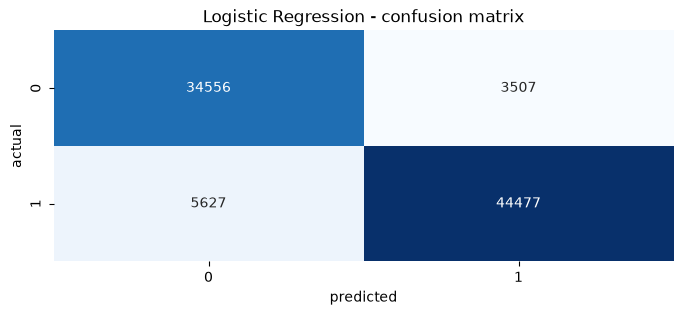


Decision Tree  ||  test accuracy: 0.9999
              precision    recall  f1-score   support

         0.0     0.9999    1.0000    0.9999     38063
         1.0     1.0000    0.9999    0.9999     50104

    accuracy                         0.9999     88167
   macro avg     0.9999    0.9999    0.9999     88167
weighted avg     0.9999    0.9999    0.9999     88167



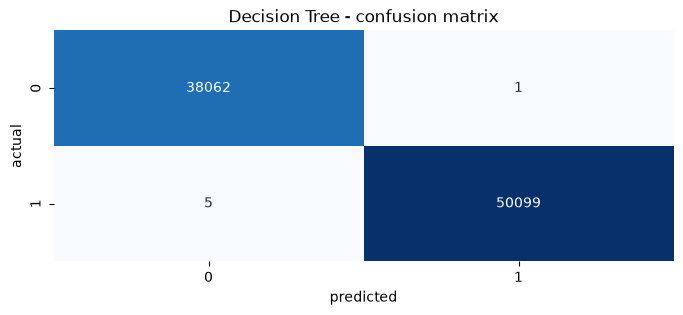


Random Forest  ||  test accuracy: 0.9991
              precision    recall  f1-score   support

         0.0     0.9979    0.9999    0.9989     38063
         1.0     1.0000    0.9984    0.9992     50104

    accuracy                         0.9991     88167
   macro avg     0.9989    0.9992    0.9991     88167
weighted avg     0.9991    0.9991    0.9991     88167



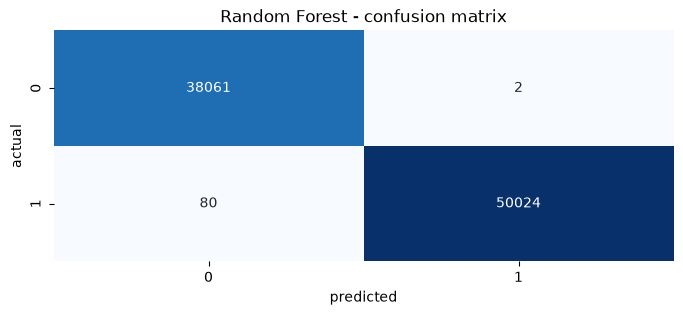


KNN  ||  test accuracy: 0.8917
              precision    recall  f1-score   support

         0.0     0.8126    0.9736    0.8859     38063
         1.0     0.9764    0.8295    0.8969     50104

    accuracy                         0.8917     88167
   macro avg     0.8945    0.9015    0.8914     88167
weighted avg     0.9057    0.8917    0.8922     88167



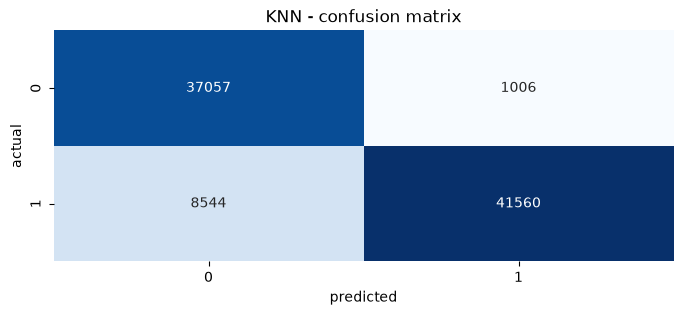


Naive Bayes  ||  test accuracy: 0.8656
              precision    recall  f1-score   support

         0.0     0.7626    0.9999    0.8652     38063
         1.0     0.9999    0.7635    0.8659     50104

    accuracy                         0.8656     88167
   macro avg     0.8812    0.8817    0.8655     88167
weighted avg     0.8974    0.8656    0.8656     88167



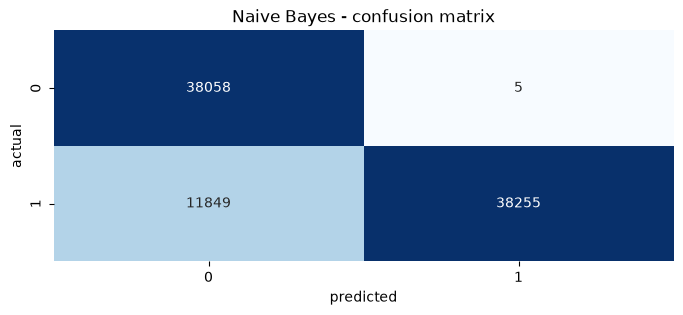

In [17]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
}

# Fixed random_state on the split and the models so these numbers reproduce.
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)

    acc_test = accuracy_score(y_test, y_pred_test)
    acc_train = accuracy_score(y_train, y_pred_train)

    results.append({"Name": name, "test_acc": acc_test, "train_acc": acc_train})

    print(f"\n{name}  ||  test accuracy: {acc_test:.4f}")
    print(classification_report(y_test, y_pred_test, digits=4))

    plt.figure(figsize=(8, 3))
    sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt="d",
                cmap="Blues", cbar=False)
    plt.title(f"{name} - confusion matrix")
    plt.ylabel("actual")
    plt.xlabel("predicted")
    plt.show()

#### Creating a database for the results and choosing the best model

In [18]:
resdf = pd.DataFrame(results).round(6)
resdf

,Name,test_acc,train_acc
0,Logistic Regression,0.896401,0.895127
1,Decision Tree,0.999932,1.000000
2,Random Forest,0.999070,1.000000
3,KNN,0.891683,0.924271
4,Naive Bayes,0.865551,0.864954


In [19]:
resdf.loc[[resdf.test_acc.idxmax()]]

,Name,test_acc,train_acc
1,Decision Tree,0.999932,1.0


## Is 99.98% a real result? A data audit

The Decision Tree scores 0.9998, and its train and test scores agree — so this is
not overfitting. That is precisely why it deserves a second look: churn is not
99.98% predictable in the real world, where the same exercise lands around
75–85%. Let's check what the data actually is.

In [20]:
# Reload the raw data so this section stands on its own.
audit = pd.read_csv("customer_churn_dataset-training-master.csv")
audit = audit.drop("CustomerID", axis=1).dropna()

numeric_cols = ["Age", "Tenure", "Usage Frequency", "Total Spend", "Last Interaction"]

stats = pd.DataFrame({
    "min": audit[numeric_cols].min(),
    "max": audit[numeric_cols].max(),
    "mean": audit[numeric_cols].mean().round(1),
    "median": audit[numeric_cols].median(),
    "skew": audit[numeric_cols].skew().round(2),
})
stats["range"] = stats["max"] - stats["min"]
stats

,min,max,mean,median,skew,range
Age,18.0,65.0,39.4,39.0,0.16,47.0
Tenure,1.0,60.0,31.3,32.0,-0.06,59.0
Usage Frequency,1.0,30.0,15.8,16.0,-0.04,29.0
Total Spend,100.0,1000.0,631.6,661.0,-0.46,900.0
Last Interaction,1.0,30.0,14.5,14.0,0.18,29.0


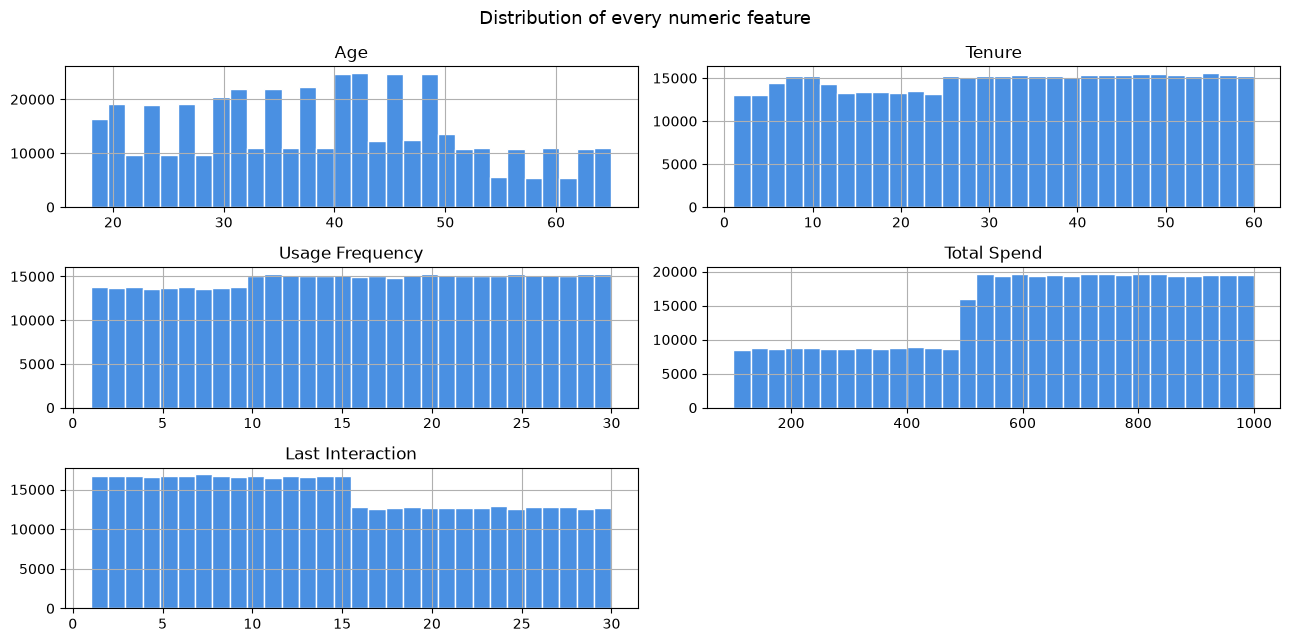

In [21]:
# Real customer data is clustered and skewed. These are flat.
audit[numeric_cols].hist(bins=30, figsize=(13, 6.5), color="#4A90E2", edgecolor="white")
plt.suptitle("Distribution of every numeric feature", fontsize=13)
plt.tight_layout()
plt.show()

In [22]:
# Are the classes separable by a handful of rules? Check the churn rate inside
# regions the tree called pure. A real dataset always has exceptions.
def churn_rate(condition, label):
    sub = audit[condition]
    print(f"{label:<50} rows={len(sub):>7}   churn rate={sub.Churn.mean():.6f}")


churn_rate(audit["Support Calls"] > 5.5,
           "Support Calls > 5.5")
churn_rate((audit["Support Calls"] <= 4) & (audit["Total Spend"] < 499.93),
           "Support Calls <= 4 and Total Spend < 499.93")
churn_rate((audit["Support Calls"] <= 4) & (audit["Total Spend"] <= 500.01),
           "Support Calls <= 4 and Total Spend <= 500.01")

Support Calls > 5.5                                rows= 118513   churn rate=1.000000
Support Calls <= 4 and Total Spend < 499.93        rows=  52699   churn rate=1.000000
Support Calls <= 4 and Total Spend <= 500.01       rows=  52826   churn rate=0.999792


In [23]:
# For completeness: the class balance is mild, so accuracy is a fair metric here.
print(audit.Churn.value_counts(normalize=True).round(4).to_string())

Churn
1.0    0.5671
0.0    0.4329


In [24]:
# How complex a model does the label actually need? A real churn boundary needs
# thousands of leaves; this one settles long before that.
audit_enc = pd.get_dummies(audit, columns=["Gender", "Subscription Type", "Contract Length"])

Xa, ya = audit_enc.drop("Churn", axis=1), audit_enc["Churn"]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=42)

complexity = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 12, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(Xa_tr, ya_tr)
    complexity.append({
        "max_depth": depth if depth is not None else "unlimited",
        "train_acc": round(tree.score(Xa_tr, ya_tr), 4),
        "test_acc": round(accuracy_score(ya_te, tree.predict(Xa_te)), 4),
        "leaves": tree.get_n_leaves(),
    })

pd.DataFrame(complexity)

,max_depth,train_acc,test_acc,leaves
0,1,0.7520,0.7533,2
1,2,0.8719,0.8728,4
2,3,0.9222,0.9232,7
3,4,0.9565,0.9568,10
4,5,0.9780,0.9775,14
5,6,0.9782,0.9777,18
6,8,0.9938,0.9936,27
7,10,0.9971,0.9970,42
8,12,0.9993,0.9992,69
9,unlimited,1.0000,0.9999,102


## Conclusion

The Decision Tree is the best model **on this dataset**, but 99.98% should not be
read as churn being 99.98% predictable.

Three things are true:

1. **The label is nearly a deterministic rule.** A tree needs only a couple of
   hundred leaves to classify 440,832 rows at 99.99%, and some regions are
   *exactly* pure — no exceptions at all in more than 100,000 rows.
2. **Every numeric feature is uniformly distributed** (skew ≈ 0, mean ≈ median
   across their whole range). Real customer behaviour is clustered and skewed;
   this is the signature of a synthetic data generator.
3. **It is not overfitting.** Train and test scores agree. The model is
   correctly learning a rule — the rule just lives in the data generator rather
   than in customer behaviour.

**So what is usable here?** The pipeline — cleaning, encoding, split, five-model
comparison, confusion matrices — is sound, and Logistic Regression's score is the
only figure that resembles a real-world churn result. What this dataset cannot
tell you is how any of these models would behave on actual customers.

Presenting the diagnosis is stronger than presenting the 99.98%: a reviewer who
sees 99.98% on churn will suspect a leak, and saying "yes — here is exactly what
causes it" is the answer they are looking for.